<a href="https://colab.research.google.com/github/iplaycos1-crypto/MBA6636/blob/main/Copy_of_MBA6636_3769291_Sun_DEA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment1 with R code by Lei Sun ID_3769291
## 1.Business Problem
### The professor faces a problem when he purchase a diamond for his girl-friend. As a common consumer, he finds it difficult to make choice and evaluate the value. Therefore he collected all diamond pricing data from three wholesalers. The objective is to identify a high-quality diamond at a reasonable price.

In [4]:
install.packages(c("tidyverse", "readxl"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [24]:
library(tidyverse)
library(readxl)
library(dplyr)
library(tibble)

##  ***1: Understanding the Data***
### Import and Read Data

In [7]:
# GitHub raw file link
data_url <- "https://raw.githubusercontent.com/iplaycos1-crypto/MBA6636/main/Professor_Proposes_Data.xlsx"


In [8]:
# Download the Excel file from My GitHub account
download.file(
  url = data_url,
  destfile = "Professor_Proposes_Data.xlsx",
  mode = "wb"
)

In [9]:
# Read the downloaded file
diamonds_data <- readxl::read_excel(
  path = "Professor_Proposes_Data.xlsx",
  sheet = "Data"
)

In [11]:
head(diamonds_data)

Carat,Colour,Clarity,Cut,Certification,Polish,Symmetry,Price,Wholesaler
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
0.92,I,SI2,G,AGS,V,V,3000,1
0.92,I,SI2,V,AGS,G,G,3000,1
0.82,F,SI2,I,GIA,X,X,3004,1
0.81,G,SI1,I,GIA,X,V,3004,1
0.90,J,VS2,V,GIA,V,V,3006,1
0.87,F,SI2,I,AGS,G,V,3007,1


In [11]:
diamonds_original <- diamonds_data    # keep the original data

### 2.Describle the dataset

In [13]:
dim(diamonds_data)

[1] 440   9

In [14]:
# 1. Number of observations (rows)
nrow(diamonds_data)

# 2. Number of variables (columns)
ncol(diamonds_data)

# 3. Display variable names and data types
str(diamonds_data)

[1] 440

[1] 9

tibble [440 × 9] (S3: tbl_df/tbl/data.frame)
 $ Carat        : num [1:440] 0.92 0.92 0.82 0.81 0.9 0.87 0.8 0.84 0.8 0.8 ...
 $ Colour       : chr [1:440] "I" "I" "F" "G" ...
 $ Clarity      : chr [1:440] "SI2" "SI2" "SI2" "SI1" ...
 $ Cut          : chr [1:440] "G" "V" "I" "I" ...
 $ Certification: chr [1:440] "AGS" "AGS" "GIA" "GIA" ...
 $ Polish       : chr [1:440] "V" "G" "X" "X" ...
 $ Symmetry     : chr [1:440] "V" "G" "X" "V" ...
 $ Price        : num [1:440] 3000 3000 3004 3004 3006 ...
 $ Wholesaler   : num [1:440] 1 1 1 1 1 1 1 1 1 1 ...


### 3.Discuss data quality issue

In [12]:
diamonds_clean <- diamonds_data       # data after clean

In [15]:
colSums(is.na(diamonds_clean))    # check missing values

Carat        Colour       Clarity           Cut Certification 
            0             0             0             0             0 
       Polish      Symmetry         Price    Wholesaler 
            0             0             0             0

In [16]:
sum(duplicated(diamonds_clean))  #count fully duplicated rows

[1] 51

#### *Two diamonds may have identical recorded characteristics and prices but still be separate legitimate observations. A duplicated row is a reason to investigate, not automatic proof of a data-entry error*

In [17]:
diamonds_clean[duplicated(diamonds_clean), ]

Carat,Colour,Clarity,Cut,Certification,Polish,Symmetry,Price,Wholesaler
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
0.80,I,VS1,I,AGS,I,I,3031,1
1.01,J,SI2,X,EGL,V,V,3139,2
1.01,J,SI2,X,EGL,V,V,3139,2
1.01,J,SI2,I,EGL,V,X,3139,2
0.22,F,SI1,V,IGI,G,G,330,3
0.23,F,SI1,X,IGI,G,G,360,3
0.28,E,VVS2,X,GIA,V,X,658,3
0.30,H,SI2,X,GIA,V,V,493,3
0.30,H,SI2,X,GIA,V,V,493,3


In [18]:
categorical_vars <- c(
  "Colour", "Clarity", "Cut",
  "Certification", "Polish",
  "Symmetry", "Wholesaler"
)

lapply(diamonds_clean[categorical_vars], unique)      # check inconsistent category labels

$Colour
[1] "I" "F" "G" "J" "D" "H" "E" "L" "K"

$Clarity
[1] "SI2"  "SI1"  "VS2"  "VS1"  "SI3"  "I2"   "I1"   "VVS2" "VVS1"

$Cut
[1] "G" "V" "I" "F" "X"

$Certification
[1] "AGS" "GIA" "EGL" "DOW" "IGI"

$Polish
[1] "V" "G" "X" "I" "v" "F"

$Symmetry
[1] "V" "G" "X" "I" "F"

$Wholesaler
[1] 1 2 3

## 2:Univariate and Bivariate Descriptive Statistic

In [19]:
diamonds_clean <- diamonds_clean %>%
  mutate(
    across(
      all_of(categorical_vars),
      ~ trimws(as.character(.x))
    )
  )                                                   # check invalid numerical values

In [20]:
summary(diamonds_clean$Carat)
summary(diamonds_clean$Price)

# Inspect potentially invalid observations
diamonds_clean %>%
  filter(
    is.na(Carat) | is.na(Price) |
      Carat <= 0 | Price <= 0
  )                                                    # check invalid numerical value

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.0900  0.3000  0.8100  0.6693  1.0100  1.5800 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    160     520    2169    1717    3012    3145 

Carat,Colour,Clarity,Cut,Certification,Polish,Symmetry,Price,Wholesaler
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>


In [21]:
data.frame(
  Stage = c("Original", "Cleaned"),
  Rows = c(
    nrow(diamonds_original),
    nrow(diamonds_clean)
  ),
  Columns = c(
    ncol(diamonds_original),
    ncol(diamonds_clean)
  )
)

Stage,Rows,Columns
<chr>,<int>,<int>
Original,440,9
Cleaned,440,9


In [22]:


variable_summary <- tibble(
  Variable = names(diamonds_clean),
  Data_Type = sapply(
    diamonds_clean,
    function(x) class(x)[1]
  ),
  Number_of_Unique_Values = sapply(
    diamonds_clean,
    function(x) dplyr::n_distinct(x, na.rm = TRUE)
  ),
  Missing_Values = sapply(
    diamonds_clean,
    function(x) sum(is.na(x))
  )
)

print(variable_summary)

# A tibble: 9 × 4
  Variable      Data_Type Number_of_Unique_Values Missing_Values
  <chr>         <chr>                       <int>          <int>
1 Carat         numeric                        50              0
2 Colour        character                       9              0
3 Clarity       character                       9              0
4 Cut           character                       5              0
5 Certification character                       5              0
6 Polish        character                       6              0
7 Symmetry      character                       5              0
8 Price         numeric                       197              0
9 Wholesaler    character                       3              0


In [24]:
data_quality <- tibble(
  Check = c(
    "Total observations",
    "Total variables",
    "Missing cells",
    "Fully duplicated rows",
    "Invalid carat values",
    "Invalid price values"
  ),
  Result = c(
    nrow(diamonds_clean),
    ncol(diamonds_clean),
    sum(is.na(diamonds_clean)),
    sum(duplicated(diamonds_clean)),
    sum(!is.na(diamonds_clean$Carat) &
          diamonds_clean$Carat <= 0),
    sum(!is.na(diamonds_clean$Price) &
          diamonds_clean$Price <= 0)
  )
)

print(data_quality)

# A tibble: 6 × 2
  Check                 Result
  <chr>                  <int>
1 Total observations       440
2 Total variables            9
3 Missing cells              0
4 Fully duplicated rows     51
5 Invalid carat values       0
6 Invalid price values       0


In [25]:
install.packages("moments")
library(moments)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



### ***Descriptive Statistics with numeric variables***

In [26]:
# Numerical summary
numeric_summary <- diamonds_clean %>%
  summarise(
    across(
      c(Carat, Price),
      list(
        n = ~sum(!is.na(.)),
        mean = ~mean(., na.rm = TRUE),
        median = ~median(., na.rm = TRUE),
        sd = ~sd(., na.rm = TRUE),
        min = ~min(., na.rm = TRUE),
        q1 = ~quantile(., 0.25, na.rm = TRUE),
        q3 = ~quantile(., 0.75, na.rm = TRUE),
        max = ~max(., na.rm = TRUE),
        skewness = ~moments::skewness(., na.rm = TRUE),
        kurtosis = ~moments::kurtosis(., na.rm = TRUE)
      ),
      .names = "{.col}_{.fn}"
    )
  )

print(numeric_summary, width= Inf)




# A tibble: 1 × 20
  Carat_n Carat_mean Carat_median Carat_sd Carat_min Carat_q1 Carat_q3 Carat_max
    <int>      <dbl>        <dbl>    <dbl>     <dbl>    <dbl>    <dbl>     <dbl>
1     440      0.669         0.81    0.380      0.09      0.3     1.01      1.58
  Carat_skewness Carat_kurtosis Price_n Price_mean Price_median Price_sd
           <dbl>          <dbl>   <int>      <dbl>        <dbl>    <dbl>
1        -0.0499           1.34     440      1717.         2169    1176.
  Price_min Price_q1 Price_q3 Price_max Price_skewness Price_kurtosis
      <dbl>    <dbl>    <dbl>     <dbl>          <dbl>          <dbl>
1       160      520    3012.      3145        -0.0518           1.18


## ***Evidence of skewness***
### The mean carat (0.669) is lower than the median carat (0.81).This suggests that the distribution may be negatively skewed, meaning that relatively small carat values may pull the mean downward. The actual Carat skewness is -0.0499, which proves my guess and gives a firm conclusion.

### ***Descriptive Statistics with categorical variables***

In [28]:

library(dplyr)

# Categorical variables in the diamond dataset
categorical_vars <- c(
  "Colour", "Clarity", "Cut",
  "Certification", "Polish",
  "Symmetry", "Wholesaler"
)

# Frequency and percentage for each categorical variable
for (v in categorical_vars) {

  cat("\nVariable:", v, "\n")

  frequency_table <- as.data.frame(
    table(diamonds_clean[[v]], useNA = "ifany")
  )

  names(frequency_table) <- c("Category", "Frequency")

  frequency_table$Percentage <- round(
    frequency_table$Frequency /
      sum(frequency_table$Frequency) * 100,
    2
  )

  print(frequency_table)
}



Variable: Colour 
  Category Frequency Percentage
1        D        20       4.55
2        E        54      12.27
3        F        58      13.18
4        G        43       9.77
5        H        71      16.14
6        I        79      17.95
7        J        72      16.36
8        K        31       7.05
9        L        12       2.73

Variable: Clarity 
  Category Frequency Percentage
1       I1        82      18.64
2       I2        28       6.36
3      SI1       116      26.36
4      SI2       110      25.00
5      SI3        26       5.91
6      VS1        30       6.82
7      VS2        41       9.32
8     VVS1         2       0.45
9     VVS2         5       1.14

Variable: Cut 
  Category Frequency Percentage
1        F        59      13.41
2        G        49      11.14
3        I        86      19.55
4        V        97      22.05
5        X       149      33.86

Variable: Certification 
  Category Frequency Percentage
1      AGS        12       2.73
2      DOW         1   

### 3.Perform bivariate analysis by taking a pair of variables

## ***3:Data Visualization***

`geom_smooth()` using formula = 'y ~ x'


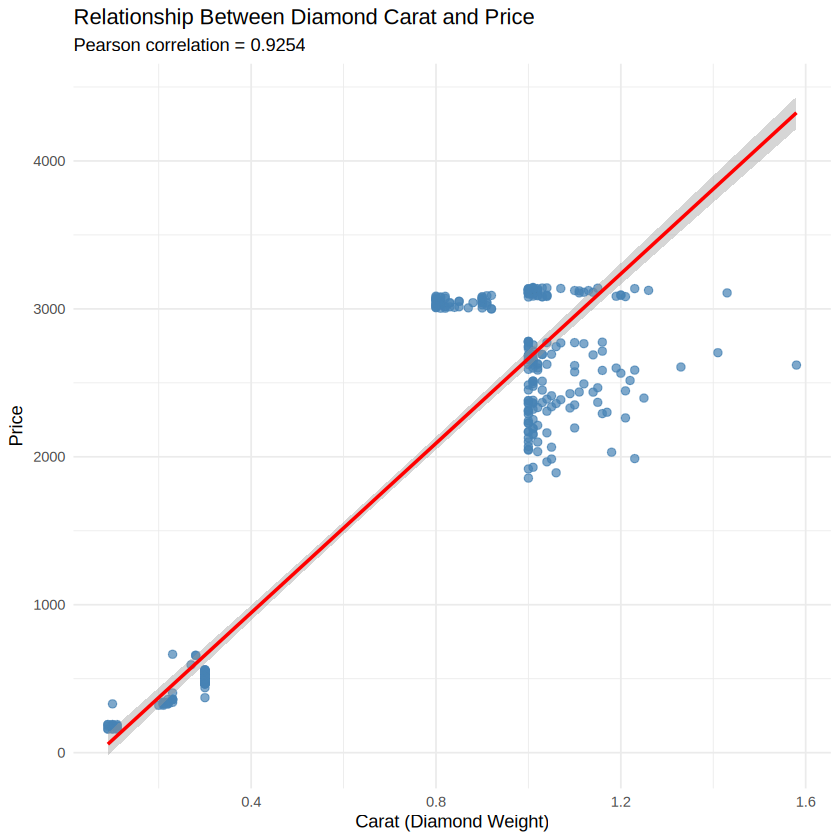

In [43]:
# Relation between Carat and Price
ggplot(diamonds_clean, aes(x = Carat, y = Price)) +
  geom_point(color = "steelblue", alpha = 0.7, size = 2) +
  geom_smooth(method = "lm", se = TRUE, color = "red") +
  labs(
    title = "Relationship Between Diamond Carat and Price",
    subtitle = "Pearson correlation = 0.9254",
    x = "Carat (Diamond Weight)",
    y = "Price"
  ) +
  theme_minimal()

### There is a strong positive correlation between carat weight and price (r = 0.925). T-test shows that p-value is much less than 0.05, we reject the null hypothesis. Diamonds with higher carat weights tend to have higher prices. However, correlation does not prove that carat weight causes higher price, because other characteristics such as colour, clarity, cut, and wholesaler may also affect price.

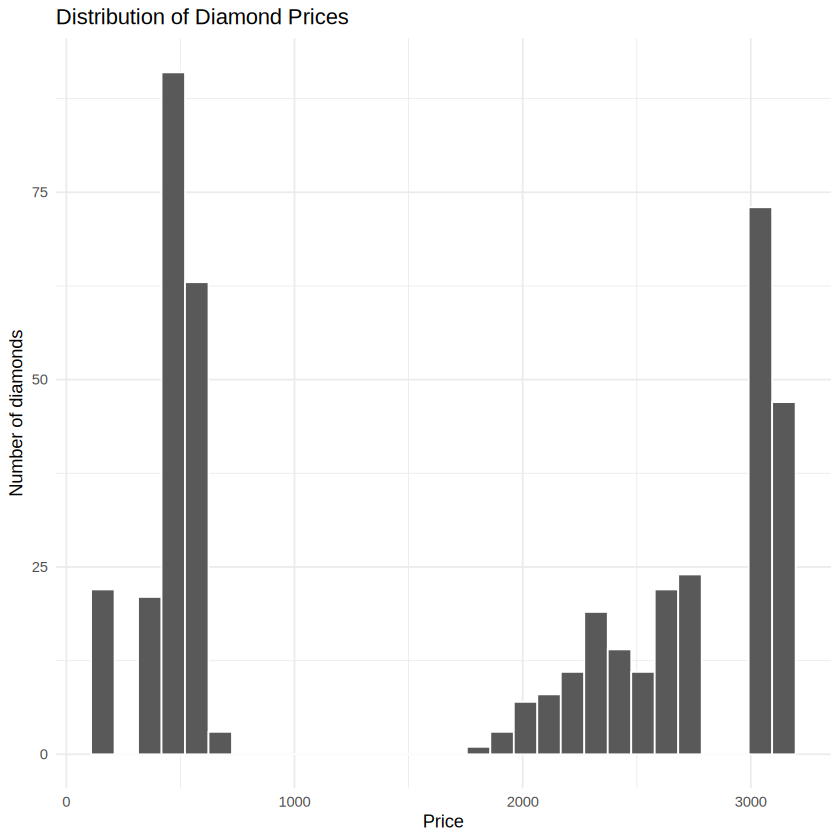

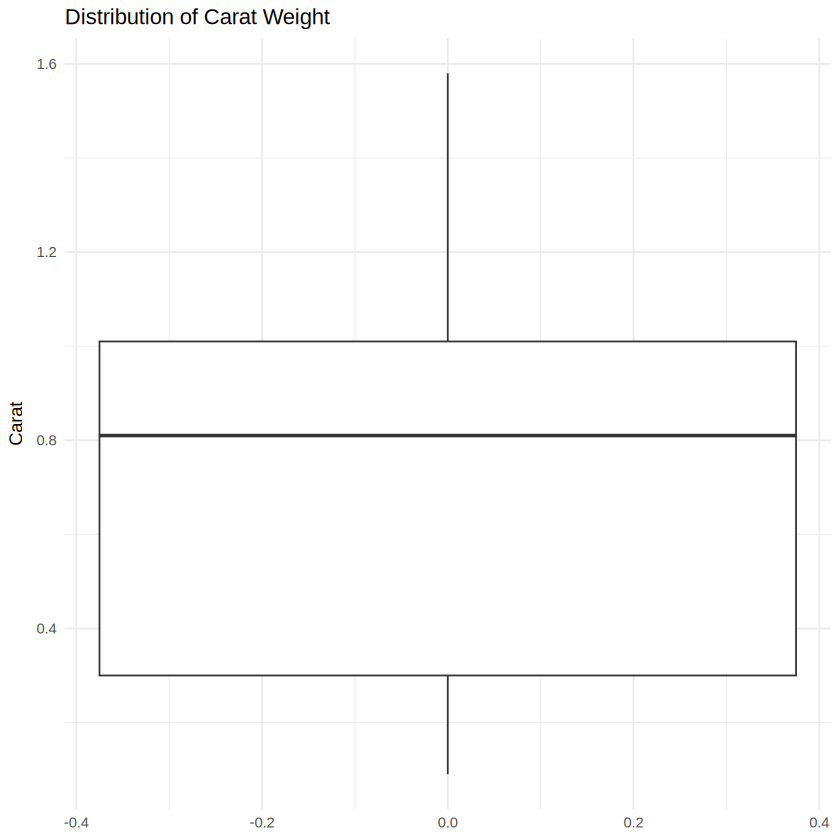

In [29]:

# 1. Histogram of price
ggplot(diamonds_clean, aes(x = Price)) +
  geom_histogram(bins = 30, colour = "white") +
  labs(title = "Distribution of Diamond Prices",
       x = "Price", y = "Number of diamonds") +
  theme_minimal()

# 2. Boxplot of carat
ggplot(diamonds_clean, aes(y = Carat)) +
  geom_boxplot() +
  labs(title = "Distribution of Carat Weight",
       y = "Carat") +
  theme_minimal()


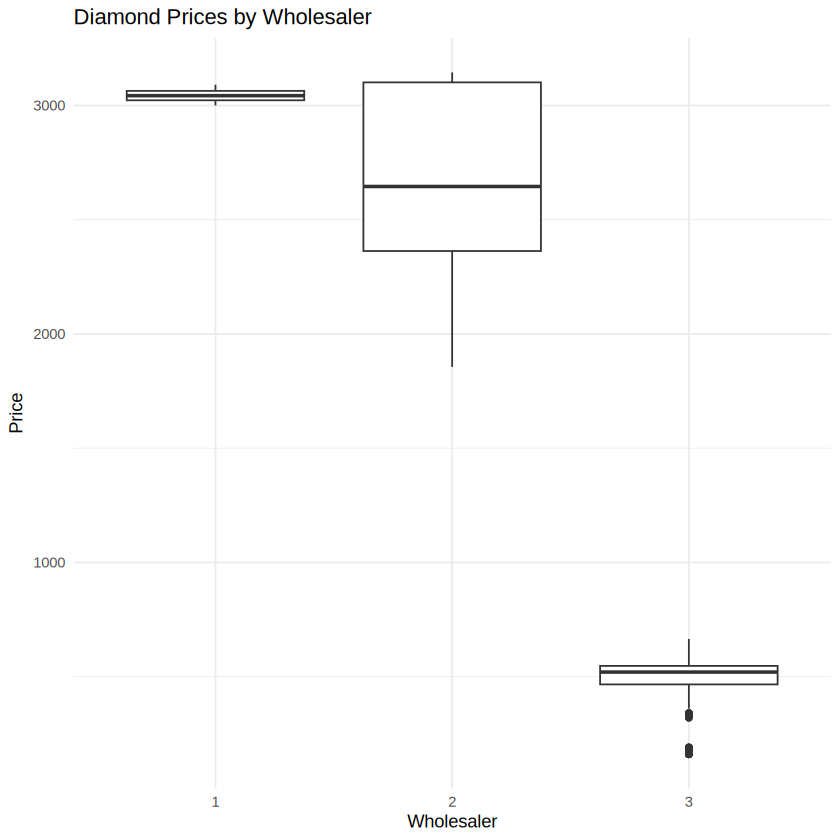

In [31]:
# 3. Wholesaler positioning boxplot
ggplot(diamonds_clean, aes(x = Wholesaler, y = Price)) +
  geom_boxplot() +
  labs(
    title = "Diamond Prices by Wholesaler",
    x = "Wholesaler",
    y = "Price"
  ) +
  theme_minimal()

### ***This chart shows that each wholesaler has a different price positioning.***

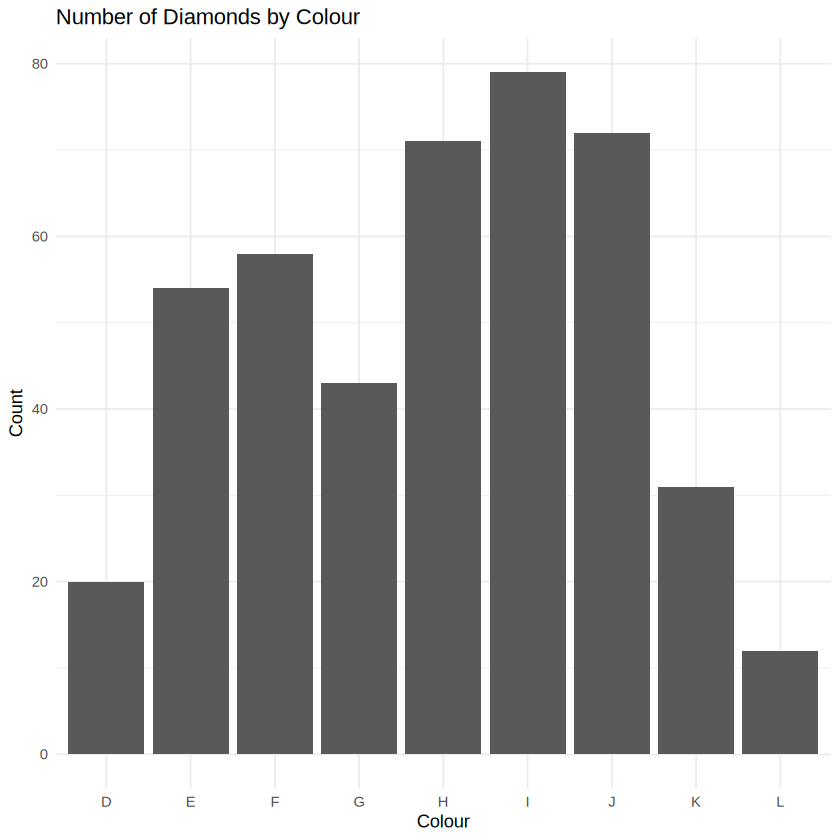

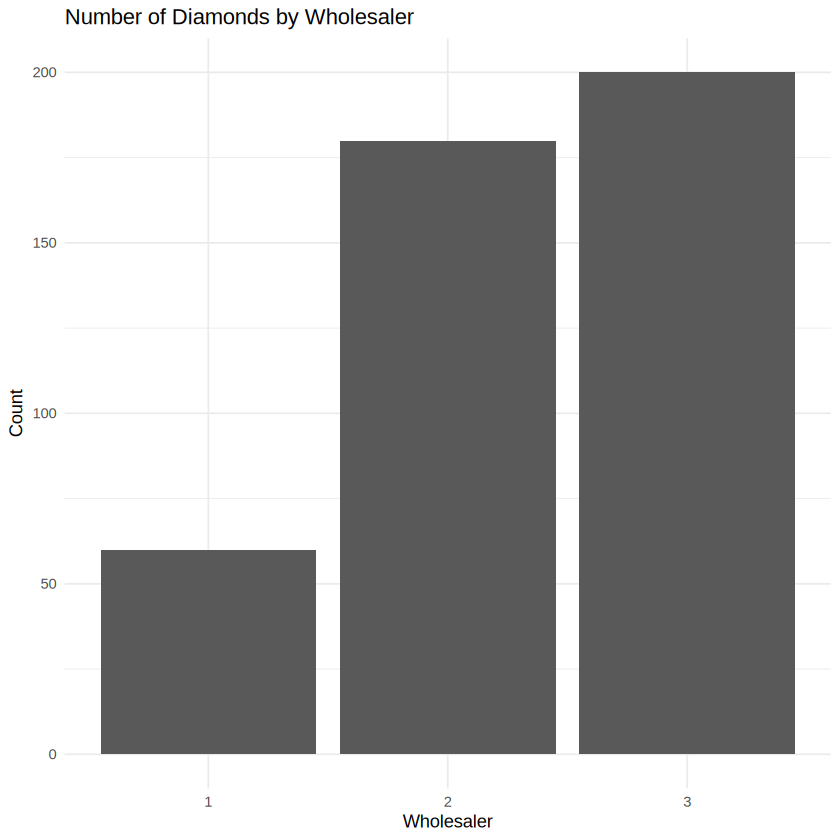

In [30]:
# 4. Colour frequency
ggplot(diamonds_clean, aes(x = Colour)) +
  geom_bar() +
  labs(title = "Number of Diamonds by Colour",
       x = "Colour", y = "Count") +
  theme_minimal()

# 5. Wholesaler frequency
ggplot(diamonds_clean, aes(x = factor(Wholesaler))) +
  geom_bar() +
  labs(title = "Number of Diamonds by Wholesaler",
       x = "Wholesaler", y = "Count") +
  theme_minimal()

## ***4.Exploring Relationships***

In [46]:

# Standardize category labels
diamonds <- diamonds_clean %>%
  mutate(
    across(
      c(Colour, Clarity, Cut, Certification,
        Polish, Symmetry),
      ~ toupper(trimws(as.character(.)))
    ),
    Wholesaler = factor(Wholesaler)
  )

# Compare prices by cut
diamonds %>%
  group_by(Cut) %>%
  summarise(
    Number = n(),
    Mean_Price = mean(Price),
    Median_Price = median(Price),
    Mean_Carat = mean(Carat),
    .groups = "drop"
  ) %>%
  arrange(desc(Median_Price))

# Compare prices by colour
diamonds %>%
  group_by(Colour) %>%
  summarise(
    Number = n(),
    Mean_Price = mean(Price),
    Median_Price = median(Price),
    Mean_Carat = mean(Carat),
    .groups = "drop"
  ) %>%
  arrange(desc(Median_Price))

# Compare prices by clarity
diamonds %>%
  group_by(Clarity) %>%
  summarise(
    Number = n(),
    Mean_Price = mean(Price),
    Median_Price = median(Price),
    Mean_Carat = mean(Carat),
    .groups = "drop"
  ) %>%
  arrange(desc(Median_Price))


Cut,Number,Mean_Price,Median_Price,Mean_Carat
<chr>,<int>,<dbl>,<dbl>,<dbl>
F,59,2455.220,2516.0,1.0071186
G,49,2046.020,2452.0,0.7685714
I,86,1731.767,2175.5,0.6132558
X,149,1658.013,2149.0,0.6874497
V,97,1178.103,531.0,0.4352577


Colour,Number,Mean_Price,Median_Price,Mean_Carat
<chr>,<int>,<dbl>,<dbl>,<dbl>
D,20,2316.200,2890.0,0.7785000
G,43,2168.465,2625.0,0.7967442
K,31,2358.258,2516.0,0.9922581
L,12,2368.500,2411.5,1.1033333
J,72,1780.917,2269.0,0.7015278
E,54,1551.907,658.0,0.5609259
H,71,1442.282,547.0,0.5791549
I,79,1550.316,547.0,0.6124051
F,58,1333.845,520.0,0.5231034


Clarity,Number,Mean_Price,Median_Price,Mean_Carat
<chr>,<int>,<dbl>,<dbl>,<dbl>
SI2,110,1974.2000,2767.5,0.6773636
SI3,26,2619.3846,2616.0,1.0419231
I1,82,2543.1463,2585.0,1.0251220
I2,28,2341.9286,2334.0,1.1392857
VVS2,5,564.2000,658.0,0.2600000
VS2,41,888.1951,547.0,0.3639024
VVS1,2,547.0000,547.0,0.3000000
SI1,116,1047.6121,545.5,0.4114655
VS1,30,1137.7667,520.0,0.4120000


In [27]:
# Correlation between carat and price
cor(
  diamonds_clean$Carat,
  diamonds_clean$Price,
  use = "complete.obs"
)          # Use only observations where both Carat and Price are available.
# Statistical test of linear correlation
cor.test(
  diamonds_clean$Carat,
  diamonds_clean$Price
)

[1] 0.925436


	Pearson's product-moment correlation

data:  diamonds_clean$Carat and diamonds_clean$Price
t = 51.116, df = 438, p-value < 2.2e-16
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.9107436 0.9377887
sample estimates:
     cor 
0.925436 


In [45]:
# Compare prices by clarity
diamonds %>%
  group_by(Certification) %>%
  summarise(
    Number = n(),
    Mean_Price = mean(Price),
    Median_Price = median(Price),
    Mean_Carat = mean(Carat),
    .groups = "drop"
  ) %>%
  arrange(desc(Median_Price))

Certification,Number,Mean_Price,Median_Price,Mean_Carat
<chr>,<int>,<dbl>,<dbl>,<dbl>
AGS,12,3033.4167,3031,0.8483333
EGL,119,2677.8319,2660,1.0358824
DOW,1,2031.0000,2031,1.1800000
GIA,265,1459.8189,547,0.5779623
IGI,43,265.5581,190,0.1553488


## ***5:Data Transformation***
### -Clean inconsistent text labels. some data cleaning and wrangling have been done in the previous steps before we describle the data.
###-Convert categorical variables into factors.
### -Identify invalid records and create a modelling dataset.
### -Transform Price and Carat using natural logarithms.

In [25]:
# Data clean and standardize the data
diamonds_clean <- diamonds_data %>%
  mutate(
    across(
      where(is.character),
      trimws
    ),
    across(
      any_of(c(
        "Colour", "Clarity", "Cut",
        "Certification", "Polish", "Symmetry"
      )),
      toupper
    )
  )

### The dataset was prepared for regression analysis through a series of data-cleaning and transformation steps. Leading and trailing spaces were removed from character variables, and categorical labels were standardized where appropriate. Diamond characteristics and wholesaler identifiers were converted to factors so that the regression model would treat them as categorical predictors.

In [28]:
# Find invalid records
invalid_records <- diamonds_clean %>%
  filter(
    is.na(Price) | is.na(Carat) |
    Price <= 0 | Carat <= 0
  )

print(invalid_records)

# A tibble: 0 × 9
# ℹ 9 variables: Carat <dbl>, Colour <chr>, Clarity <chr>, Cut <chr>,
#   Certification <chr>, Polish <chr>, Symmetry <chr>, Price <dbl>,
#   Wholesaler <dbl>



Call:
lm(formula = log_price ~ log_carat + Colour + Clarity + Cut + 
    Certification + Polish + Symmetry + Wholesaler, data = diamonds_model)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.29573 -0.03161  0.00255  0.02284  0.53793 

Coefficients: (1 not defined because of singularities)
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)       7.890094   0.046492 169.709  < 2e-16 ***
log_carat         0.852372   0.025554  33.356  < 2e-16 ***
ColourE          -0.057048   0.018523  -3.080  0.00221 ** 
ColourF          -0.110237   0.018552  -5.942 6.07e-09 ***
ColourG          -0.101719   0.019064  -5.336 1.59e-07 ***
ColourH          -0.123003   0.018621  -6.606 1.25e-10 ***
ColourI          -0.160088   0.018693  -8.564 2.30e-16 ***
ColourJ          -0.226019   0.019768 -11.434  < 2e-16 ***
ColourK          -0.313854   0.022578 -13.901  < 2e-16 ***
ColourL          -0.382611   0.027357 -13.986  < 2e-16 ***
ClarityI2        -0.224942   0.018093 -12.432 

(Intercept)        log_carat          ColourE          ColourF 
     7.890094219      0.852372051     -0.057047843     -0.110236559 
         ColourG          ColourH          ColourI          ColourJ 
    -0.101718677     -0.123002850     -0.160088094     -0.226019007 
         ColourK          ColourL        ClarityI2       ClaritySI1 
    -0.313853744     -0.382611387     -0.224941661      0.303429827 
      ClaritySI2       ClaritySI3       ClarityVS1       ClarityVS2 
     0.246218270      0.125841313      0.360561113      0.348192344 
     ClarityVVS1      ClarityVVS2             CutG             CutI 
     0.503704930      0.519483147      0.007431790      0.032089411 
            CutV             CutX CertificationDOW CertificationEGL 
     0.034032427      0.033218397     -0.153557734     -0.130347520 
CertificationGIA CertificationIGI          PolishG          PolishI 
    -0.003110776     -0.212016920      0.024848870      0.077688191 
         PolishV          PolishX        SymmetryG        SymmetryI 
     0.041318849      0.040584627      0.047572831               NA 
       SymmetryV        SymmetryX      Wholesaler2      Wholesaler3 
     0.047957061      0.042882113      0.061762836     -0.868320158

Warning message:
“not plotting observations with leverage one:
  68”


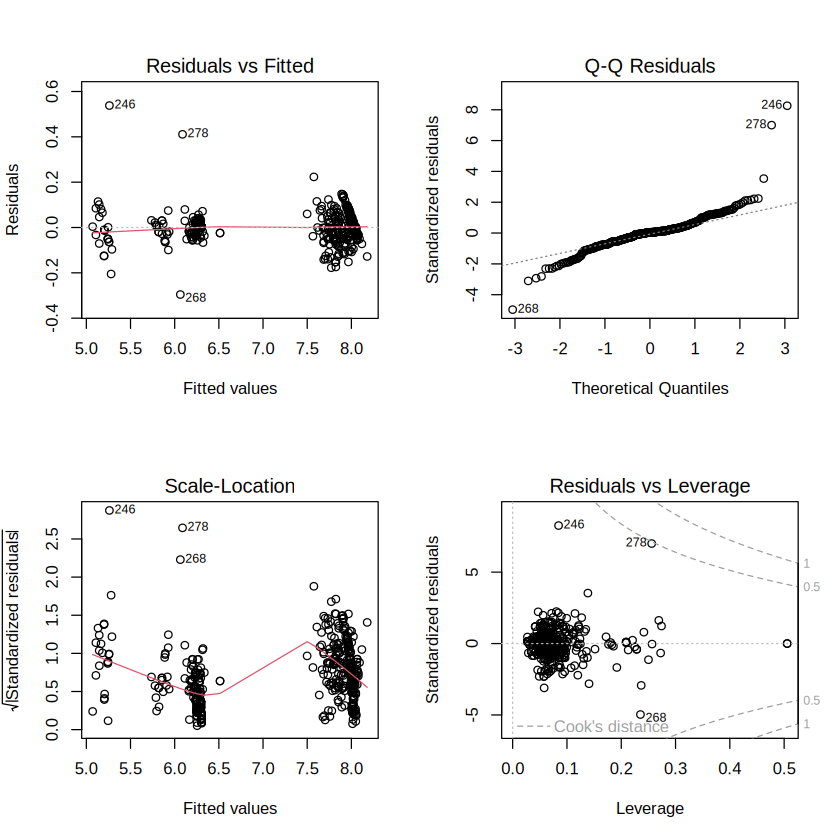

In [26]:

# Treat diamond characteristics as categories
diamonds_model <- diamonds_clean %>%
  filter(Carat > 0, Price > 0) %>%
  mutate(
    log_price = log(Price),
    log_carat = log(Carat),
    across(
      c(Colour, Clarity, Cut, Certification,
        Polish, Symmetry, Wholesaler),
      as.factor
    )
  ) %>%
  droplevels()

# Estimate the regression model
price_model <- lm(
  log_price ~ log_carat + Colour + Clarity + Cut +
    Certification + Polish + Symmetry + Wholesaler,
  data = diamonds_model
)

# Review model results
summary(price_model)

# Examine the estimated coefficients
coef(price_model)

# Check the model diagnostics
par(mfrow = c(2, 2))
plot(price_model)
par(mfrow = c(1, 1))



In [29]:
# Treat diamond characteristics as categories
diamonds_model <- diamonds_clean %>%
  filter(Carat > 0, Price > 0) %>%
  mutate(
    log_price = log(Price),
    log_carat = log(Carat),
    across(
      c(Colour, Clarity, Cut, Certification,
        Polish, Symmetry, Wholesaler),
      as.factor
    )
  ) %>%
  droplevels()

  # Estimate the regression model
price_model <- lm(
  log_price ~ log_carat + Colour + Clarity + Cut +
    Certification + Polish + Symmetry + Wholesaler,
  data = diamonds_model
)
summary(price_model)


Call:
lm(formula = log_price ~ log_carat + Colour + Clarity + Cut + 
    Certification + Polish + Symmetry + Wholesaler, data = diamonds_model)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.29573 -0.03161  0.00255  0.02284  0.53793 

Coefficients: (1 not defined because of singularities)
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)       7.890094   0.046492 169.709  < 2e-16 ***
log_carat         0.852372   0.025554  33.356  < 2e-16 ***
ColourE          -0.057048   0.018523  -3.080  0.00221 ** 
ColourF          -0.110237   0.018552  -5.942 6.07e-09 ***
ColourG          -0.101719   0.019064  -5.336 1.59e-07 ***
ColourH          -0.123003   0.018621  -6.606 1.25e-10 ***
ColourI          -0.160088   0.018693  -8.564 2.30e-16 ***
ColourJ          -0.226019   0.019768 -11.434  < 2e-16 ***
ColourK          -0.313854   0.022578 -13.901  < 2e-16 ***
ColourL          -0.382611   0.027357 -13.986  < 2e-16 ***
ClarityI2        -0.224942   0.018093 -12.432 

In [30]:

# Model with a possible interaction
interaction_model <- lm(
  log_price ~ log_carat * Colour + Clarity +
    Cut + Certification + Polish + Symmetry +
    Wholesaler,
  data = diamonds_model
)

summary(interaction_model)

# Compare models
anova(price_model, interaction_model)



Call:
lm(formula = log_price ~ log_carat * Colour + Clarity + Cut + 
    Certification + Polish + Symmetry + Wholesaler, data = diamonds_model)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.30226 -0.02775 -0.00144  0.02520  0.53948 

Coefficients: (1 not defined because of singularities)
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)        7.896110   0.048376 163.224  < 2e-16 ***
log_carat          0.836933   0.034166  24.496  < 2e-16 ***
ColourE           -0.051071   0.022481  -2.272   0.0236 *  
ColourF           -0.113314   0.023117  -4.902 1.39e-06 ***
ColourG           -0.098665   0.022302  -4.424 1.25e-05 ***
ColourH           -0.131810   0.022778  -5.787 1.46e-08 ***
ColourI           -0.157415   0.022290  -7.062 7.39e-12 ***
ColourJ           -0.211489   0.022645  -9.339  < 2e-16 ***
ColourK           -0.310420   0.024065 -12.899  < 2e-16 ***
ColourL           -0.417099   0.036330 -11.481  < 2e-16 ***
ClarityI2         -0.227565   0.018

,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,405,1.876087,NA,NA,NA,NA
2,397,1.827778,8,0.04830884,1.311607,0.2358428


In [31]:
# 5. Create target-diamond scenarios
new_diamond <- data.frame(
  Carat = rep(0.90, 3),
  Colour = rep("J", 3),
  Clarity = rep("SI2", 3),
  Cut = rep("V", 3),
  Certification = rep("GIA", 3),
  Polish = rep("G", 3),
  Symmetry = rep("V", 3),
  Wholesaler = c("1", "2", "3")
)

# Match factor levels to the modelling data
for (v in categorical_vars) {
  new_diamond[[v]] <- factor(
    new_diamond[[v]],
    levels = levels(diamonds_model[[v]])
  )
}

new_diamond$log_carat <- log(new_diamond$Carat)

# 6. Predict price and calculate prediction intervals
pred <- predict(
  price_model,
  newdata = new_diamond,
  interval = "prediction",
  level = 0.95
)

price_results <- data.frame(
  Wholesaler = new_diamond$Wholesaler,
  Estimated_Price = exp(pred[, "fit"]),
  Lower_Prediction = exp(pred[, "lwr"]),
  Upper_Prediction = exp(pred[, "upr"])
)

print(price_results)

  Wholesaler Estimated_Price Lower_Prediction Upper_Prediction
1          1        2763.393         2404.901         3175.325
2          2        2939.449         2553.094         3384.271
3          3        1159.674         1000.823         1343.739


## ***Analyze the professor's 3100 purchase diamond case***
### The model predicted prices of 2,763.39, 2,939.45, and 1,159.67 for Wholesalers 1, 2, and 3, respectively. At the asking price of 3,100, the diamond is priced above the model’s point estimates for Wholesalers 1 and 2, although the asking price falls within both prediction intervals. but the labeled price 3100 is among the confidence intervals with the Wholesale 1,2. therefore, the regression results alone do not establish that the diamond is overpriced.

## ***My recommendation***
### My regression gives the professor a useful price benchmark. I recommend the professor to consider negotiating toward the model estimates for Wholesalers 1 and 2.